# Where does an $87B pension fund put its money?
### NYCERS holdings, FY2017 to FY2024

The New York City Employees' Retirement System (NYCERS) publishes a position-level snapshot of its holdings each fiscal year (fiscal years end June 30). This notebook uses seven of those snapshots to answer five questions:

1. How big is the fund, and how has its mix of asset types changed?
2. How concentrated is the public-equity book, and in which sectors?
3. How global is it?
4. What did the 2022 rate shock do to the bond portfolio?
5. Has the bond book's credit risk changed?

**Data:** NYC Office of the Comptroller, *NYCERS Holdings Data* (NYC Open Data, export dated 2025-10-08). The raw file is cleaned by [`src/nycers/clean.py`](../src/nycers/clean.py); every rule is listed in the cleaning log below.

**A note on "returns".** The dataset has market value, cost basis and unrealized gain/loss for each position at each snapshot. It does **not** have cash flows, so it cannot give a time-weighted return. Unrealized gain as a % of cost is used here as a measure of *how far positions are above or below what was paid*, not as a performance figure.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from nycers import metrics as m
from nycers.style import (use_matplotlib_style, SEGMENT_COLORS, CREDIT_COLORS,
                          ACCENT, NEUTRAL, GAIN, LOSS, TEXT_2)

use_matplotlib_style()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.3f}".format)
billions = mtick.FuncFormatter(lambda x, _: f"${x/1e9:,.0f}B")
pct = mtick.PercentFormatter(1.0, decimals=0)
billions2 = mtick.FuncFormatter(lambda x, _: f"${x/1e9:,.1f}B")
def year_axis(ax):
    ax.set_xticks(YEARS); ax.set_xticklabels([str(y) for y in YEARS])

df = m.load(ROOT / "data" / "processed" / "holdings_clean.parquet")
YEARS = sorted(df["fiscal_year"].unique())
print(f"{len(df):,} positions across fiscal years {YEARS}")

244,361 positions across fiscal years [np.int16(2017), np.int16(2019), np.int16(2020), np.int16(2021), np.int16(2022), np.int16(2023), np.int16(2024)]


## 0. Data quality

The raw export has 299,944 rows. About 1 in 5 of them should not be analysed as-is.

In [2]:
log = json.loads((ROOT / "data" / "processed" / "cleaning_log.json").read_text())
pd.Series(log, name="value").to_frame()

,value
raw_rows,299944
dropped_placeholder_1899_rows,48350
dropped_blank_rows,119
dropped_exact_duplicates,7113
duplicate_market_value_usd,"7,106,177.230"
dropped_orphan_2015_rows,1
fixed_groupt_trust_typo,40994
clean_rows,244361
fiscal_years,"[2017, 2019, 2020, 2021, 2022, 2023, 2024]"


What the cleaning does, and why:

| Issue | Rows | Treatment |
|---|---:|---|
| Placeholder rows dated `12/31/1899`, every field `0` | 48,350 | Dropped. They carry no information. |
| Completely blank rows (FY2021) | 119 | Dropped. |
| Exact duplicate rows | 7,113 | Dropped. Their total value is about $7M, under 0.01% of assets. |
| One position dated FY2015 | 1 | Dropped. No other FY2015 data exists. |
| `Groupt Trust` typo | 40,994 | Fixed to `Group Trust`. |
| Two spellings of the United States | ~100k | Merged. |
| Ratings like `Ba1u`, `(P)B3`, `A-p`, `BAA3`, `- 0`, `NR`, `WR` | | Normalised to standard S&P and Moody's scales. Unrated becomes missing. |

Things this analysis deliberately does **not** do, unlike many tutorials on this kind of data:

* **No outlier removal.** In a portfolio, the "outliers" are the biggest positions (US Treasuries, Microsoft, Apple). Removing them with an IQR rule removes the story.
* **No log transforms or scaling before aggregation.** Dollar values are summed, so they must stay in dollars.
* **No mixing of years.** Each fiscal year is a separate snapshot of the same fund. Pooling them counts Apple seven times.
* **No imputing missing ratings.** Equities don't have credit ratings. A missing rating on a bond is reported as "Not rated", not filled in.

FY2018 is missing from the source, so year-over-year comparisons across 2017 to 2019 span two years.

## 1. Size and asset mix

In [3]:
tot = m.totals_by_year(df)
tot.assign(market_value_bn=tot.market_value / 1e9)[["fiscal_year", "market_value_bn", "positions", "securities", "unrealized_pct_of_cost"]]

,fiscal_year,market_value_bn,positions,securities,unrealized_pct_of_cost
0,2017,60.385,30359,14178,0.205
1,2019,68.226,41170,16322,0.086
2,2020,70.087,40425,16115,0.076
3,2021,87.921,29437,15583,0.234
4,2022,77.040,38754,16258,0.057
5,2023,80.529,31049,15931,0.117
6,2024,86.675,33167,16692,0.152


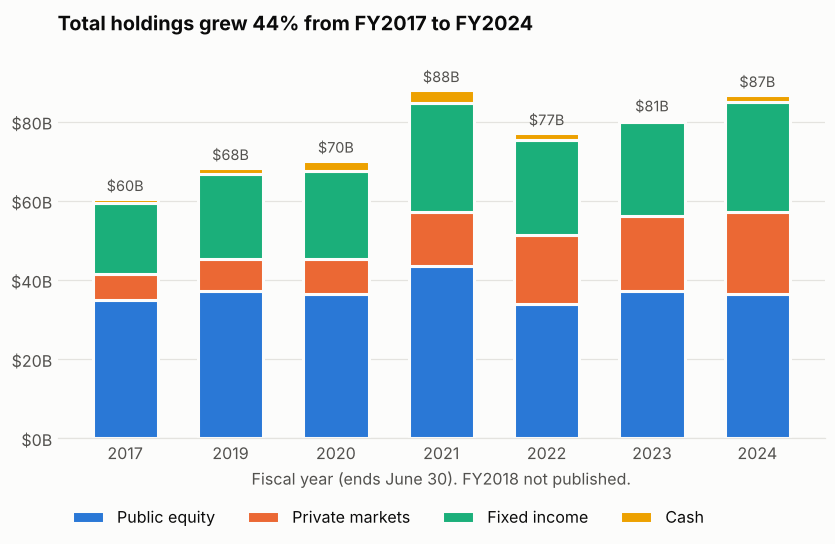

In [4]:
mix = m.segment_mix(df)
wide = mix.pivot(index="fiscal_year", columns="segment", values="market_value")[m.SEGMENT_ORDER]

fig, ax = plt.subplots(figsize=(9, 4.6))
x = [str(y) for y in wide.index]
bottom = pd.Series(0.0, index=wide.index)
for seg in m.SEGMENT_ORDER:
    ax.bar(x, wide[seg], bottom=bottom, color=SEGMENT_COLORS[seg], width=0.62,
           edgecolor="#fcfcfb", linewidth=2, label=seg)
    bottom += wide[seg]
for xi, v in zip(x, bottom):
    ax.text(xi, v + 1.2e9, f"${v/1e9:,.0f}B", ha="center", va="bottom", fontsize=9.5, color=TEXT_2)
ax.yaxis.set_major_formatter(billions)
ax.set_ylim(0, bottom.max() * 1.12)
ax.set_title("Total holdings grew 44% from FY2017 to FY2024")
ax.set_xlabel("Fiscal year (ends June 30). FY2018 not published.")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.14))
fig.savefig(FIG / "01_total_holdings.png"); plt.show()

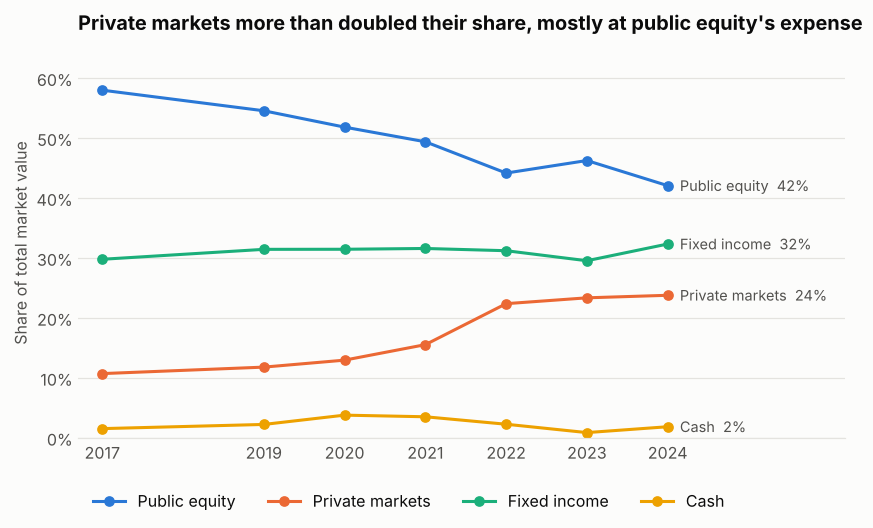

segment,Public equity,Private markets,Fixed income,Cash
fiscal_year,,,,
2017,0.580,0.107,0.298,0.015
2019,0.546,0.118,0.314,0.022
2020,0.518,0.130,0.314,0.038
2021,0.494,0.155,0.316,0.035
2022,0.442,0.224,0.312,0.023
2023,0.463,0.233,0.295,0.009
2024,0.421,0.238,0.323,0.018


In [5]:
share = mix.pivot(index="fiscal_year", columns="segment", values="share")[m.SEGMENT_ORDER]
fig, ax = plt.subplots(figsize=(9, 4.6))
for seg in m.SEGMENT_ORDER:
    ax.plot(share.index, share[seg], color=SEGMENT_COLORS[seg], marker="o", label=seg)
    ax.annotate(f"{seg}  {share[seg].iloc[-1]:.0%}", (share.index[-1], share[seg].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9.5, color=TEXT_2)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.65)
ax.set_xlim(share.index.min() - 0.3, share.index.max() + 2.2); year_axis(ax)
ax.set_title("Private markets more than doubled their share, mostly at public equity's expense")
ax.set_ylabel("Share of total market value")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=4)
fig.savefig(FIG / "02_asset_mix.png"); plt.show()
share.round(3)

**Finding 1.** Holdings grew from **$60.4B to $86.7B** (+44%), with one down year: FY2022 fell 12% as both stocks and bonds sold off.

**Finding 2.** The big allocation story is the move into **private markets** (limited-partnership interests in private equity, private credit and real estate funds; the source labels them `VENTURE CAPITAL`). They grew from **$6.5B (11%) to $20.6B (24%)**, while public equity fell from **58% to 42%**. Fixed income stayed close to 30% throughout.

Caveat: private-market values are appraisals reported with a lag, so their share tends to jump in years when public markets fall (FY2022). Part of that jump is a "denominator effect", not new money.

## 2. Inside the public-equity book

In [6]:
conc = m.concentration(df)
conc

,fiscal_year,top10_share,hhi,effective_n,issuers
0,2017,0.086,0.002,506.143,9470
1,2019,0.090,0.002,476.485,9984
2,2020,0.119,0.003,314.669,9620
3,2021,0.114,0.003,345.445,10749
4,2022,0.123,0.003,298.043,10567
5,2023,0.135,0.004,252.997,10484
6,2024,0.154,0.004,233.455,10788


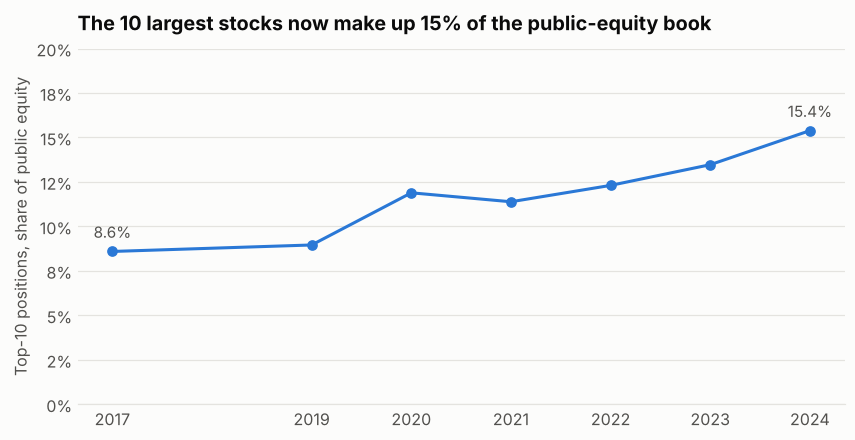

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(conc.fiscal_year, conc.top10_share, color=ACCENT, marker="o")
for _, r in conc.iloc[[0, -1]].iterrows():
    ax.annotate(f"{r.top10_share:.1%}", (r.fiscal_year, r.top10_share), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=10, color=TEXT_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.set_ylim(0, 0.2); year_axis(ax)
ax.set_title("The 10 largest stocks now make up 15% of the public-equity book")
ax.set_ylabel("Top-10 positions, share of public equity")
fig.savefig(FIG / "03_concentration.png"); plt.show()

In [8]:
top24 = m.top_holdings(df, 2024, n=10)
top17 = m.top_holdings(df, 2017, n=10)
pd.concat({"FY2017": top17, "FY2024": top24}, axis=1)

FY2017                                   \
                security_name    market_value share_of_segment   
0                   APPLE INC 540,608,882.140            0.015   
1              MICROSOFT CORP 374,503,791.490            0.011   
2   AFL CIO HOUSING INV TRUST 305,509,768.310            0.009   
3  UBS TRUMBULL PROPERTY FUND 277,805,814.890            0.008   
4  SAMSUNG ELECTRONICS CO LTD 263,693,990.300            0.008   
5            EXXON MOBIL CORP 261,732,149.640            0.007   
6              AMAZON.COM INC 256,145,271.570            0.007   
7           JOHNSON + JOHNSON 246,883,037.540            0.007   
8         JPMORGAN CHASE + CO 245,986,191.000            0.007   
9              FACEBOOK INC A 235,064,109.430            0.007   

                         FY2024                                     
                  security_name      market_value share_of_segment  
0                MICROSOFT CORP 1,079,410,620.050            0.030  
1                     APPLE INC 1,015,457,151.120            0.028  
2                   NVIDIA CORP   924,785,601.720            0.025  
3                AMAZON.COM INC   589,625,654.750            0.016  
4  TAIWAN SEMICONDUCTOR MANUFAC   393,995,493.800            0.011  
5    META PLATFORMS INC CLASS A   372,270,163.980            0.010  
6             ALPHABET INC CL A   358,728,395.800            0.010  
7     AFL CIO HOUSING INV TRUST   319,260,614.500            0.009  
8             ALPHABET INC CL C   297,736,331.580            0.008  
9   BERKSHIRE HATHAWAY INC CL B   257,366,088.000            0.007

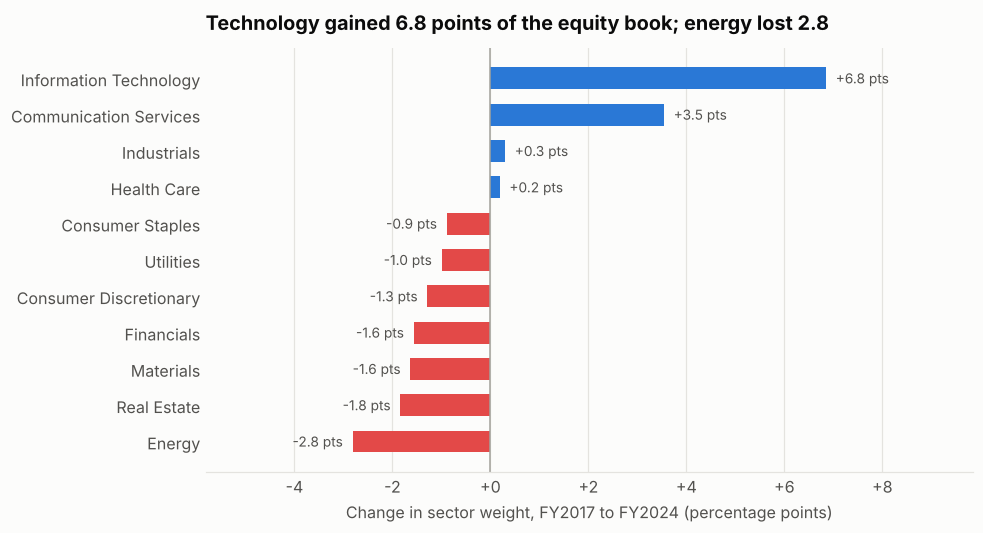

fiscal_year,2017,2019,2020,2021,2022,2023,2024
sector,,,,,,,
UTILITIES,0.031,0.035,0.029,0.022,0.032,0.027,0.021
ENERGY,0.057,0.055,0.031,0.028,0.031,0.031,0.029
REAL ESTATE,0.055,0.052,0.046,0.041,0.050,0.040,0.037
MATERIALS,0.058,0.057,0.053,0.053,0.051,0.048,0.042
CONSUMER STAPLES,0.071,0.069,0.069,0.058,0.070,0.070,0.062
COMMUNICATION SERVICES,0.028,0.065,0.069,0.071,0.059,0.062,0.064
HEALTH CARE,0.108,0.108,0.126,0.120,0.135,0.125,0.110
CONSUMER DISCRETIONARY,0.130,0.113,0.118,0.142,0.114,0.120,0.117
INDUSTRIALS,0.120,0.112,0.105,0.116,0.110,0.120,0.123


In [9]:
# GICS moved Telecom into the new Communication Services sector in 2018, so merge them,
# and leave out rows that are not sectors (cash sweep, commingled funds).
eq = df[df.segment == "Public equity"].copy()
eq["sector"] = eq["major_industry"].astype(str).replace({"TELECOMMUNICATION SERVICES": "COMMUNICATION SERVICES"})
eq = eq[~eq.sector.isin(["CASH EQUIVALENT", "COMMINGLED FUND"])]
sect = eq.groupby(["sector", "fiscal_year"]).market_value.sum().unstack(fill_value=0)
sect = sect / sect.sum()
sect = sect[sect.max(axis=1) > 0.02].sort_values(2024)
change = (sect[2024] - sect[2017]).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
colors = [GAIN if v > 0 else LOSS for v in change]
ax.barh(change.index.str.title(), change.values, color=colors, height=0.6)
for i, v in enumerate(change.values):
    ax.text(v + (0.002 if v >= 0 else -0.002), i, f"{v*100:+.1f} pts", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=TEXT_2)
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v*100:+.0f}"))
ax.set_xlim(change.min() - 0.03, change.max() + 0.03)
ax.set_title(f"Technology gained {change.max()*100:.1f} points of the equity book; energy lost {-change['ENERGY']*100:.1f}")
ax.set_xlabel("Change in sector weight, FY2017 to FY2024 (percentage points)")
fig.savefig(FIG / "04_sector_shift.png"); plt.show()
sect.round(3)

**Finding 3.** The public-equity book is getting **more concentrated**. The top 10 positions went from **8.6% to 15.4%** of it, and the "effective number" of equally weighted holdings (1 / HHI) fell from about **506 to 233**, even though the fund holds over 10,000 issuers. Microsoft, Apple and Nvidia alone are about **8%** of public equity in FY2024. Alphabet appears twice (class A and C shares), so its true weight is about 1.8%.

This mostly reflects the market itself: an index-like portfolio inherits the market's concentration in mega-cap tech. Measured as a share of sector-classified stocks, **information technology** rose from 17.7% to 24.6%, while **energy** fell from 5.7% to 2.9%. In 2017 the top 10 still included Exxon, Johnson & Johnson and JPMorgan. By 2024 it is almost all tech.

Note: in 2018 the GICS standard moved Telecom into a new Communication Services sector, along with Alphabet and Meta (from IT and Consumer Discretionary). The chart merges Telecom into Communication Services; the tech gain would be larger without that reclassification.

## 3. How global is it?

In [10]:
us = m.us_share(df)
cm = m.country_mix(df)
top_c = cm[cm.fiscal_year == 2024].nlargest(8, "share")
print("US share of public equity by year:"); display(us.round(3))
top_c.assign(share_of_non_us=top_c.share.round(3))[["country", "market_value", "share_of_non_us"]]

US share of public equity by year:


,fiscal_year,us_share
0,2017,0.643
1,2019,0.642
2,2020,0.666
3,2021,0.650
4,2022,0.664
5,2023,0.672
6,2024,0.636


,country,market_value,share_of_non_us
340,JAPAN,"1,685,677,279.550",0.127
365,UNITED KINGDOM,"1,377,272,485.550",0.104
333,HONG KONG,"1,275,374,888.200",0.096
361,TAIWAN (PROVINCE OF CHINA),"915,109,649.460",0.069
330,FRANCE,"898,537,133.290",0.068
335,INDIA,"826,758,179.180",0.062
360,SWITZERLAND,"767,833,178.820",0.058
331,GERMANY,"741,210,919.270",0.056


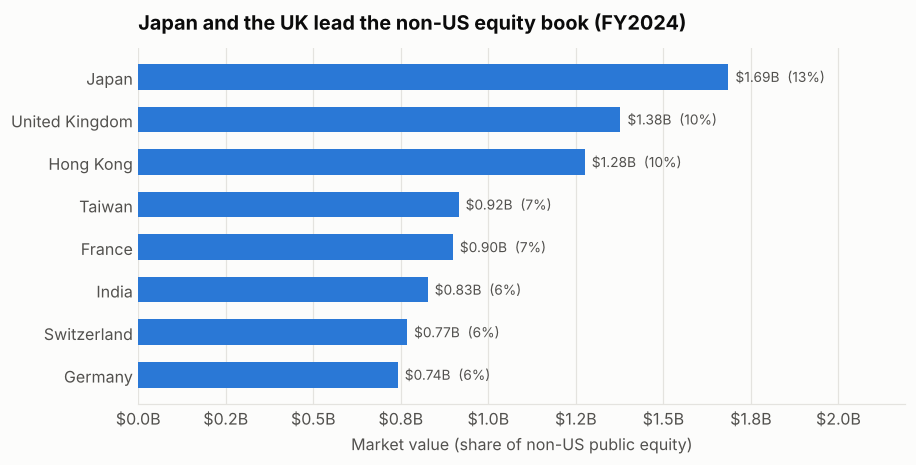

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
s = top_c.sort_values("share")
ax.barh(s.country.str.replace(r" \(.*\)", "", regex=True).str.title(), s.market_value, color=ACCENT, height=0.6)
for i, (v, sh) in enumerate(zip(s.market_value, s.share)):
    ax.text(v + 2e7, i, f"${v/1e9:,.2f}B  ({sh:.0%})", va="center", fontsize=9, color=TEXT_2)
ax.xaxis.set_major_formatter(billions2); ax.set_xlim(0, s.market_value.max() * 1.3)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Japan and the UK lead the non-US equity book (FY2024)")
ax.set_xlabel("Market value (share of non-US public equity)")
fig.savefig(FIG / "05_countries.png"); plt.show()

**Finding 4.** About **two thirds of public equity is US**, and that share barely moved (64% to 67% across all seven years). The fund holds stocks listed in about 50 countries. Japan, the UK, Hong Kong and Taiwan are the largest non-US positions.

## 4. The 2022 rate shock in the bond book

In [12]:
ug = m.unrealized_by_segment(df)
ugw = ug.pivot(index="fiscal_year", columns="segment", values="unrealized_pct_of_cost")
fi = m.fixed_income_profile(df)
display(ugw.round(3)); fi

segment,Cash,Fixed income,Private markets,Public equity
fiscal_year,,,,
2017,0.000,0.009,0.170,0.353
2019,0.000,0.028,0.192,0.105
2020,0.000,0.050,0.079,0.098
2021,0.000,0.022,0.254,0.440
2022,-0.001,-0.104,0.332,0.084
2023,-0.001,-0.094,0.249,0.238
2024,-0.001,-0.053,0.224,0.339


,fiscal_year,wavg_coupon,wavg_years_to_maturity,wavg_rating_notch,unrealized_gl,unrealized_pct_of_cost
0,2017,3.025,11.514,5.294,"167,929,696.440",0.009
1,2019,3.034,11.721,4.490,"588,142,522.160",0.028
2,2020,3.070,13.811,5.327,"1,053,114,341.430",0.050
3,2021,2.768,13.436,5.474,"608,997,253.030",0.022
4,2022,2.660,12.729,5.275,"-2,780,302,454.280",-0.104
5,2023,3.118,12.418,5.191,"-2,453,453,735.250",-0.094
6,2024,3.906,12.652,6.136,"-1,557,750,900.200",-0.053


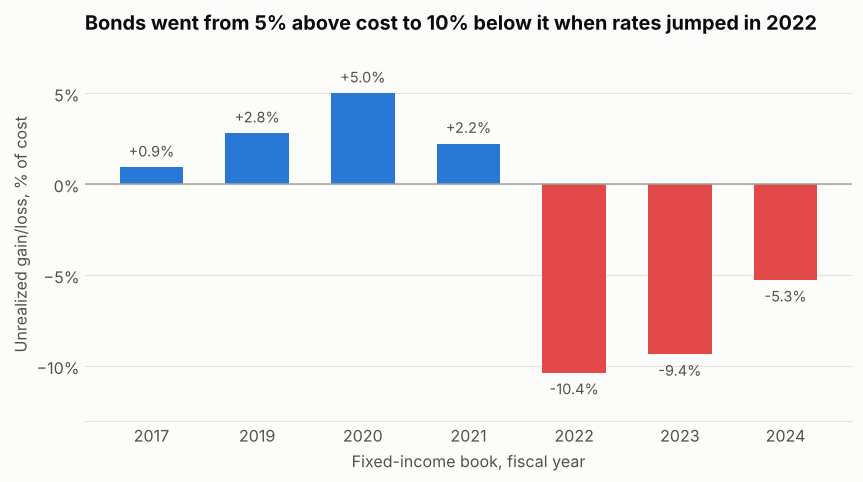

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.4))
v = fi.set_index("fiscal_year")["unrealized_pct_of_cost"]
ax.bar([str(y) for y in v.index], v.values, color=[GAIN if x >= 0 else LOSS for x in v], width=0.6)
for xi, val in zip([str(y) for y in v.index], v.values):
    ax.text(xi, val + (0.004 if val >= 0 else -0.004), f"{val:+.1%}", ha="center",
            va="bottom" if val >= 0 else "top", fontsize=9.5, color=TEXT_2)
ax.axhline(0, color=NEUTRAL, linewidth=1)
ax.yaxis.set_major_formatter(pct); ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05)); ax.set_ylim(-0.13, 0.075)
ax.set_title("Bonds went from 5% above cost to 10% below it when rates jumped in 2022")
ax.set_ylabel("Unrealized gain/loss, % of cost")
ax.set_xlabel("Fixed-income book, fiscal year")
fig.savefig(FIG / "06_bond_unrealized.png"); plt.show()

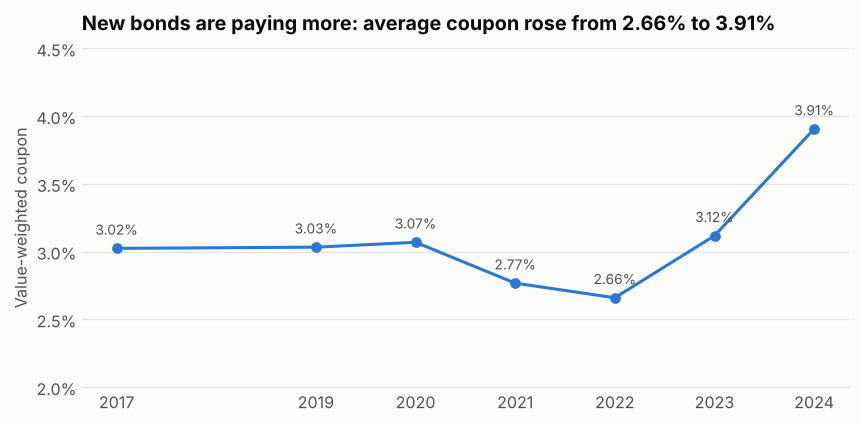

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.0))
ax.plot(fi.fiscal_year, fi.wavg_coupon / 100, color=ACCENT, marker="o")
for _, r in fi.iterrows():
    ax.annotate(f"{r.wavg_coupon:.2f}%", (r.fiscal_year, r.wavg_coupon / 100), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9, color=TEXT_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1)); ax.set_ylim(0.02, 0.045); year_axis(ax)
ax.set_title("New bonds are paying more: average coupon rose from 2.66% to 3.91%")
ax.set_ylabel("Value-weighted coupon")
fig.savefig(FIG / "07_coupon.png"); plt.show()

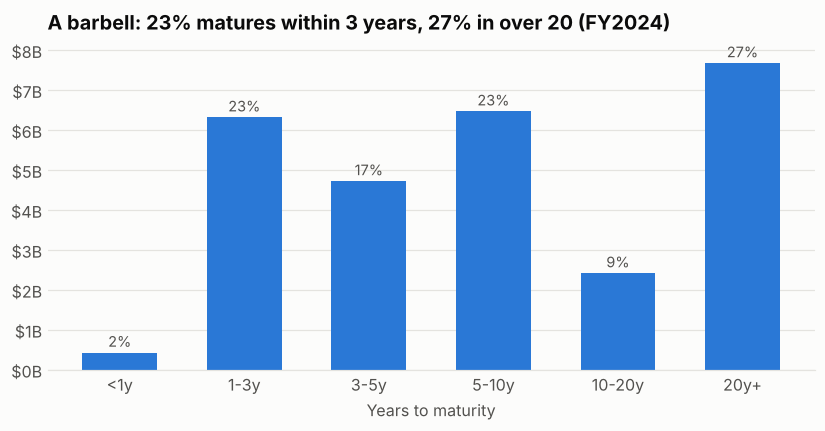

In [15]:
lad = m.maturity_ladder(df, 2024)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(lad.maturity_bucket.astype(str), lad.market_value, color=ACCENT, width=0.6)
for xi, (val, sh) in enumerate(zip(lad.market_value, lad.share)):
    ax.text(xi, val + 1.5e8, f"{sh:.0%}", ha="center", fontsize=9.5, color=TEXT_2)
ax.yaxis.set_major_formatter(billions)
ax.set_title("A barbell: 23% matures within 3 years, 27% in over 20 (FY2024)")
ax.set_xlabel("Years to maturity")
fig.savefig(FIG / "08_maturity.png"); plt.show()

**Finding 5.** When interest rates rose sharply in 2022, bond prices fell. The fixed-income book went from **+5.0% above cost (FY2020)** to **-10.4% below cost (FY2022)**, a swing from about **+$1.1B to -$2.8B** in unrealized value. It was still **-5.3%** (-$1.6B) in FY2024. These are paper losses: a bond held to maturity pays back its face value, so this gap closes over time.

The other side of that shock: money reinvested after 2022 earns more. The value-weighted **coupon rose from 2.66% to 3.91%** between FY2022 and FY2024. The bond book is a **barbell**, with 23% maturing within 3 years and 27% in more than 20 (mostly Treasuries and mortgage-backed securities). The long end is the part most sensitive to rate moves.

## 5. Credit quality

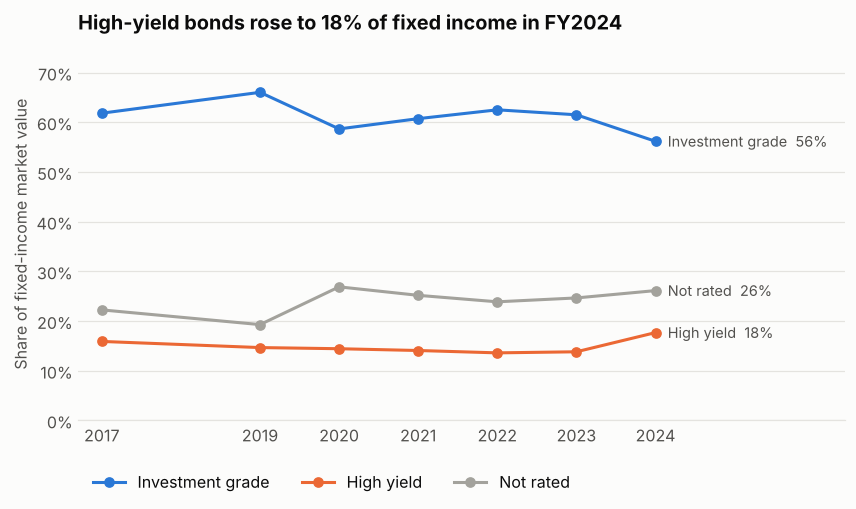

credit_bucket,Investment grade,High yield,Not rated
fiscal_year,,,
2017,0.618,0.159,0.223
2019,0.660,0.147,0.193
2020,0.587,0.144,0.269
2021,0.607,0.141,0.252
2022,0.625,0.136,0.239
2023,0.615,0.138,0.247
2024,0.562,0.177,0.261


In [16]:
cr = m.credit_mix(df)
crw = cr.pivot(index="fiscal_year", columns="credit_bucket", values="share")[list(CREDIT_COLORS)]
fig, ax = plt.subplots(figsize=(9, 4.4))
for b in CREDIT_COLORS:
    ax.plot(crw.index, crw[b], color=CREDIT_COLORS[b], marker="o", label=b)
    ax.annotate(f"{b}  {crw[b].iloc[-1]:.0%}", (crw.index[-1], crw[b].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9.5, color=TEXT_2)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.75)
ax.set_xlim(crw.index.min() - 0.3, crw.index.max() + 2.4); year_axis(ax)
ax.set_title("High-yield bonds rose to 18% of fixed income in FY2024")
ax.set_ylabel("Share of fixed-income market value")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=3)
fig.savefig(FIG / "09_credit_mix.png"); plt.show()
crw.round(3)

In [17]:
fi24 = df[(df.segment == "Fixed income") & (df.fiscal_year == 2024)]
(fi24.assign(credit_bucket=fi24.credit_bucket.astype("string").fillna("Not rated"))
     .pivot_table(index="investment_type", columns="credit_bucket", values="market_value",
                  aggfunc="sum", observed=True).div(1e9).round(2).fillna(0)
     .sort_values("Investment grade", ascending=False))

credit_bucket,High yield,Investment grade,Not rated
investment_type,,,
GOVERNMENT ISSUES,0.000,9.490,0.310
CORPORATE BONDS,4.860,5.320,0.040
CONVERTIBLE BONDS,0.090,0.480,0.800
CMO,0.000,0.190,0.500
AUTO LOAN RECEIVABLE,0.000,0.120,0.000
OTHER ASSET BACKED,0.000,0.090,0.400
CREDIT CARD RCVEABLE,0.000,0.030,0.000
MUNICIPALS,0.000,0.020,0.000
BANK LOAN,0.000,0.000,0.400


**Finding 6.** Credit risk crept up in the latest year. **High-yield** (below BBB- / Baa3) rose from **13.6% to 17.7%** of the bond book between FY2022 and FY2024, and investment grade fell from 62.5% to 56.2%. That fits the higher coupons above: part of the extra income comes from taking more credit risk. Most "Not rated" value is agency mortgage-backed securities (FNMA, FHLMC, GNMA) and bank loans. Agency MBS carry an implicit government guarantee, so "not rated" doesn't mean "risky" here.

Rule used when both agencies rate a bond: take the **lower** of the two ratings (conservative).

## Summary

| # | Finding |
|---|---|
| 1 | Holdings grew from $60.4B to $86.7B (FY2017 to FY2024). FY2022 was the only down year, at -12%. |
| 2 | Private markets went from 11% to 24% of the fund. Public equity fell from 58% to 42%. |
| 3 | The top-10 share of public equity nearly doubled, from 8.6% to 15.4%. Tech rose from 18% to 25% of the equity book. |
| 4 | About two thirds of public equity is in the US, and that share has been stable. |
| 5 | The 2022 rate shock turned the bond book from +5.0% to -10.4% vs cost. The average coupon has since risen to 3.91%. |
| 6 | High-yield rose from 13.6% to 17.7% of fixed income in FY2024. |

**Limitations.** Snapshots are once a year, so nothing here says what happened between June 30s. There is no FY2018. There are no cash flows, so no time-weighted returns. Private-market values are lagged appraisals. Security names aren't unique IDs (no CUSIP/ISIN in the data), so tracking a holding across years relies on name matching.